# Notebook 06 — Model Refinement and Remedial Measures

Notebook 05 identified substantial heteroskedasticity and right-skewed residuals in the candidate OLS specifications.

This notebook investigates remedial measures for these diagnostic problems. A log transformation of `TotalAmount` is considered first, followed by weighted least squares (WLS) to address remaining unequal error variance. Heteroskedasticity-robust inference is also examined as a robustness check.

All model refinement is conducted using the model-building sample. The validation sample is not used in model development.

## 1. Reconstruct the Model-Building Sample

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import statsmodels.formula.api as smf

from scipy.stats import norm
from statsmodels.stats.diagnostic import het_breuschpagan

In [2]:
PROJECT_DIR = Path.cwd().resolve()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_DIR = PROJECT_DIR / "outputs"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_FILE = (
    PROCESSED_DATA_DIR
    / "db1c_ticket_prepared_202606.parquet"
)

df = pd.read_parquet(DATA_FILE)

print(f"Rows:    {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

Rows:    90,086
Columns: 16


### 1.1 Reproduce the 50/50 Split

In [3]:
SPLIT_SEED = 42
TRAIN_SHARE = 0.50

rng = np.random.default_rng(SPLIT_SEED)

random_order = rng.permutation(len(df))
split_point = int(TRAIN_SHARE * len(df))

train_idx = random_order[:split_point]
validation_idx = random_order[split_point:]

model_df = (
    df.iloc[train_idx]
    .copy()
    .reset_index(drop=True)
)

validation_df = (
    df.iloc[validation_idx]
    .copy()
    .reset_index(drop=True)
)

print(f"Model-building sample: {len(model_df):,}")
print(f"Validation sample:     {len(validation_df):,}")

Model-building sample: 45,043
Validation sample:     45,043


### 1.2 Reproduce Categorical Grouping

In [4]:
MIN_CATEGORY_COUNT = 100

carrier_counts = model_df["RpCarrier"].value_counts()

major_carriers = carrier_counts[
    carrier_counts >= MIN_CATEGORY_COUNT
].index

model_df["RpCarrier_Model"] = model_df["RpCarrier"].where(
    model_df["RpCarrier"].isin(major_carriers),
    "Other"
)

validation_df["RpCarrier_Model"] = validation_df["RpCarrier"].where(
    validation_df["RpCarrier"].isin(major_carriers),
    "Other"
)

state_counts = model_df["OriginState"].value_counts()

major_states = state_counts[
    state_counts >= MIN_CATEGORY_COUNT
].index

model_df["OriginState_Model"] = model_df["OriginState"].where(
    model_df["OriginState"].isin(major_states),
    "Other"
)

validation_df["OriginState_Model"] = validation_df["OriginState"].where(
    validation_df["OriginState"].isin(major_states),
    "Other"
)

print(
    f"Carrier model categories: "
    f"{model_df['RpCarrier_Model'].nunique()}"
)

print(
    f"Origin-state model categories: "
    f"{model_df['OriginState_Model'].nunique()}"
)

Carrier model categories: 12
Origin-state model categories: 43


#### Interpretation

The same 50/50 split and categorical grouping rules used in Notebooks 03–05 are reproduced.

Category definitions are determined exclusively from the model-building sample. The validation sample is not used to make any model-development decisions and remains reserved for final validation.

## 2. Baseline Specification

The full eight-block level model is used as the baseline for model refinement.

Notebook 05 showed that removing `Coupons` produced almost no change in residual behaviour or influence diagnostics. The initial refinement therefore focuses on the response specification and error structure rather than further variable deletion.

In [5]:
baseline_formula = """
TotalAmount ~
    TotalDistance
    + Coupons
    + C(RoundTrip, Treatment(reference=0))
    + C(OnLine, Treatment(reference=1))
    + C(PurchaseWindowGroup, Treatment(reference='21AP'))
    + C(RpCarrier_Model, Treatment(reference='AA'))
    + C(ItinGeoType, Treatment(reference=2))
    + C(OriginState_Model, Treatment(reference='CA'))
"""

baseline_model = smf.ols(
    formula=baseline_formula,
    data=model_df
).fit()

print(f"Observations: {int(baseline_model.nobs):,}")
print(f"R-squared:    {baseline_model.rsquared:.6f}")

Observations: 45,043
R-squared:    0.385439


## 3. Log Transformation of TotalAmount

Notebook 05 identified strong right-skewness and increasing residual variance in the level specification.

Because `TotalAmount` is strictly positive, a log transformation is considered:

$$
Y_i^*=\log(\text{TotalAmount}_i).
$$

The same predictor specification is retained so that changes in residual behaviour can be attributed to the response transformation.

In [6]:
model_df["LogTotalAmount"] = np.log(
    model_df["TotalAmount"]
)

print(
    model_df[
        ["TotalAmount", "LogTotalAmount"]
    ].describe()
)

        TotalAmount  LogTotalAmount
count  45043.000000    45043.000000
mean     459.573963        5.905780
std      352.251989        0.689761
min        1.000000        0.000000
25%      242.400000        5.490589
50%      388.400000        5.962036
75%      580.400000        6.363718
max     7620.500000        8.938597


### 3.1 Fit the Log-Response Model

In [7]:
log_formula = """
LogTotalAmount ~
    TotalDistance
    + Coupons
    + C(RoundTrip, Treatment(reference=0))
    + C(OnLine, Treatment(reference=1))
    + C(PurchaseWindowGroup, Treatment(reference='21AP'))
    + C(RpCarrier_Model, Treatment(reference='AA'))
    + C(ItinGeoType, Treatment(reference=2))
    + C(OriginState_Model, Treatment(reference='CA'))
"""

log_model = smf.ols(
    formula=log_formula,
    data=model_df
).fit()

print(f"Observations: {int(log_model.nobs):,}")
print(f"R-squared:    {log_model.rsquared:.6f}")

Observations: 45,043
R-squared:    0.574214


#### Interpretation

The log-response model explains approximately 57.4% of the variation in `LogTotalAmount`.

This $R^2$ applies to the log-fare scale and should not be directly compared with the level-model $R^2$ because the dependent variable has changed.

The residual diagnostics are examined next to assess whether the transformation improves model adequacy.

### 3.2 Residuals Versus Fitted Values

The residual-versus-fitted plot is re-examined after transformation to determine whether the fan-shaped variance pattern observed in the level model has been reduced.

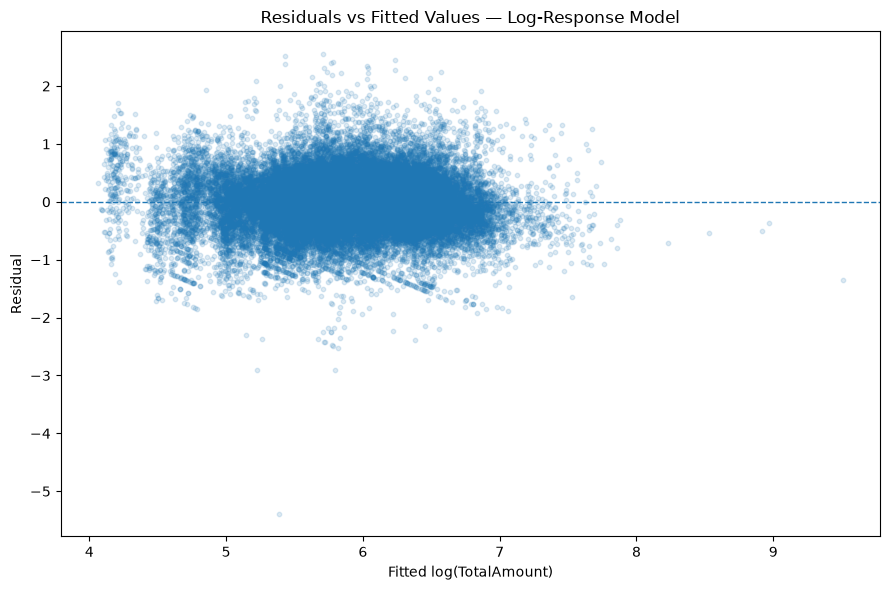

In [8]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    log_model.fittedvalues,
    log_model.resid,
    alpha=0.15,
    s=10
)

ax.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

ax.set_xlabel("Fitted log(TotalAmount)")
ax.set_ylabel("Residual")
ax.set_title(
    "Residuals vs Fitted Values — Log-Response Model"
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "06_log_model_residuals_vs_fitted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Interpretation

The residual spread is more balanced than under the level specification, and the pronounced fan shape is visually reduced.

However, some nonconstant spread remains, so the log transformation improves the residual pattern without fully resolving the variance issue.

### 3.3 Residual Distribution

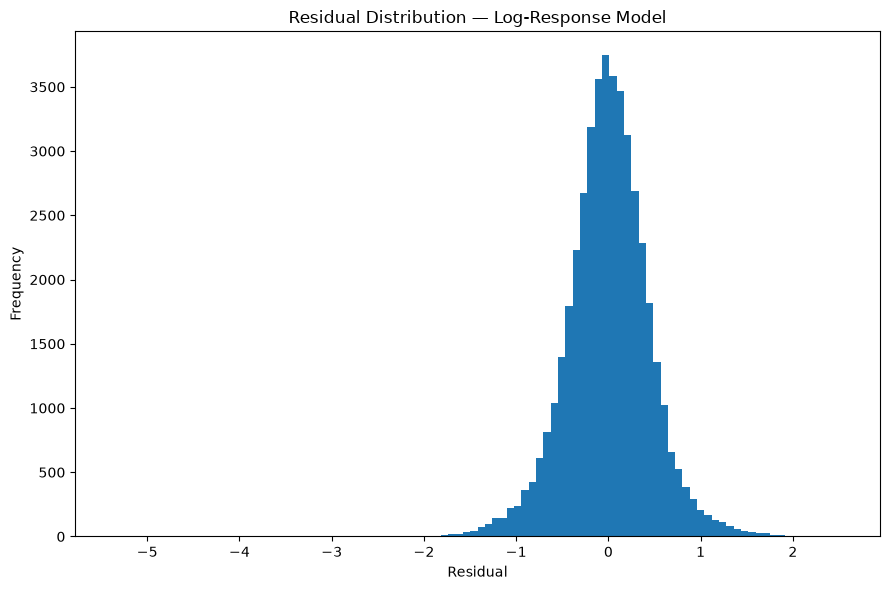

In [9]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(
    log_model.resid,
    bins=100
)

ax.set_xlabel("Residual")
ax.set_ylabel("Frequency")
ax.set_title(
    "Residual Distribution — Log-Response Model"
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "06_log_model_residual_histogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
def pp_plot(residuals, title, output_file):

    residuals = np.asarray(residuals)

    standardized = (
        residuals - residuals.mean()
    ) / residuals.std(ddof=1)

    standardized = np.sort(standardized)

    n = len(standardized)

    empirical_prob = (
        np.arange(1, n + 1) - 0.5
    ) / n

    theoretical_prob = norm.cdf(
        standardized
    )

    fig, ax = plt.subplots(figsize=(7, 7))

    ax.scatter(
        theoretical_prob,
        empirical_prob,
        alpha=0.4,
        s=10
    )

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        linewidth=1
    )

    ax.set_xlabel(
        "Theoretical Normal Cumulative Probability"
    )

    ax.set_ylabel(
        "Observed Cumulative Probability"
    )

    ax.set_title(title)

    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR / output_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

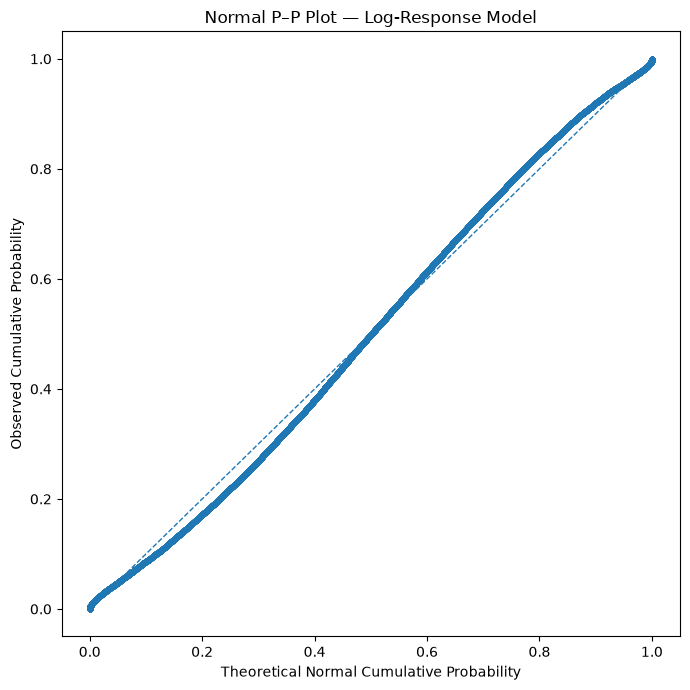

In [11]:
pp_plot(
    log_model.resid,
    "Normal P–P Plot — Log-Response Model",
    "06_log_model_pp_plot.png"
)

#### Interpretation

The residual distribution is substantially more symmetric after the log transformation, and the extreme positive tail is greatly reduced.

The normal P–P plot also lies much closer to the 45-degree reference line than under the level specification. Some tail departures remain, but the severe non-normality observed in Notebook 05 is substantially reduced.

### 3.4 Breusch–Pagan Test

The Breusch–Pagan test is repeated to determine whether heteroskedasticity remains after the log transformation.

In [12]:
log_bp = het_breuschpagan(
    log_model.resid,
    log_model.model.exog
)

log_bp_results = pd.DataFrame({
    "Statistic": [
        "LM Statistic",
        "LM p-value",
        "F Statistic",
        "F p-value"
    ],
    "Value": log_bp
})

display(log_bp_results)

,Statistic,Value
0,LM Statistic,1681.851629
1,LM p-value,0.000000
2,F Statistic,29.078662
3,F p-value,0.000000


In [13]:
baseline_bp = het_breuschpagan(
    baseline_model.resid,
    baseline_model.model.exog
)

heteroskedasticity_comparison = pd.DataFrame({
    "Model": [
        "Level model",
        "Log-response model"
    ],
    "LM_Statistic": [
        baseline_bp[0],
        log_bp[0]
    ],
    "LM_p_value": [
        baseline_bp[1],
        log_bp[1]
    ],
    "F_Statistic": [
        baseline_bp[2],
        log_bp[2]
    ],
    "F_p_value": [
        baseline_bp[3],
        log_bp[3]
    ]
})

display(heteroskedasticity_comparison)

heteroskedasticity_comparison.to_csv(
    OUTPUT_DIR / "06_heteroskedasticity_comparison.csv",
    index=False
)

,Model,LM_Statistic,LM_p_value,F_Statistic,F_p_value
0,Level model,1590.790017,5.633910e-293,27.446597,0.0
1,Log-response model,1681.851629,0.000000e+00,29.078662,0.0


#### Interpretation

The Breusch–Pagan test strongly rejects constant error variance for the log-response model:

$$
LM=1681.85,
\qquad
p<0.001.
$$

Thus, although the log transformation substantially improves the residual distribution, heteroskedasticity remains.

The log-response OLS model therefore still does not satisfy the constant-variance condition required for BLUE, motivating the WLS analysis in Section 4.

## 4. Weighted Least Squares

The log transformation improves the residual distribution, but unequal error variance remains.

Following the empirical WLS procedure, absolute OLS residuals are used to estimate the error standard deviation. The fitted standard deviations are then converted into weights:

$$
w_i=\frac{1}{\hat{\sigma}_i^2}.
$$

WLS gives relatively greater weight to observations with lower estimated error variance.

### 4.1 Examine the Error-Variance Pattern

In [14]:
wls_data = model_df.copy()

wls_data["Fitted_LogFare"] = (
    log_model.fittedvalues.to_numpy()
)

wls_data["Abs_Residual"] = np.abs(
    log_model.resid.to_numpy()
)

In [15]:
wls_data["Fitted_Bin"] = pd.qcut(
    wls_data["Fitted_LogFare"],
    q=20,
    duplicates="drop"
)

variance_pattern = (
    wls_data
    .groupby(
        "Fitted_Bin",
        observed=True
    )
    .agg(
        Mean_Fitted=(
            "Fitted_LogFare",
            "mean"
        ),
        Mean_Abs_Residual=(
            "Abs_Residual",
            "mean"
        ),
        Median_Abs_Residual=(
            "Abs_Residual",
            "median"
        ),
        N=(
            "Abs_Residual",
            "size"
        )
    )
    .reset_index(drop=True)
)

display(variance_pattern)

,Mean_Fitted,Mean_Abs_Residual,Median_Abs_Residual,N
0,4.690671,0.476113,0.401472,2253
1,5.108957,0.373428,0.292954,2252
2,5.328057,0.359283,0.288378,2252
3,5.452278,0.348761,0.275932,2252
4,5.546176,0.338449,0.272311,2252
5,5.626762,0.310456,0.242441,2252
6,5.698613,0.360654,0.282639,2252
7,5.762241,0.329448,0.257386,2256
8,5.823083,0.335549,0.269884,2248
9,5.892290,0.326724,0.251262,2253


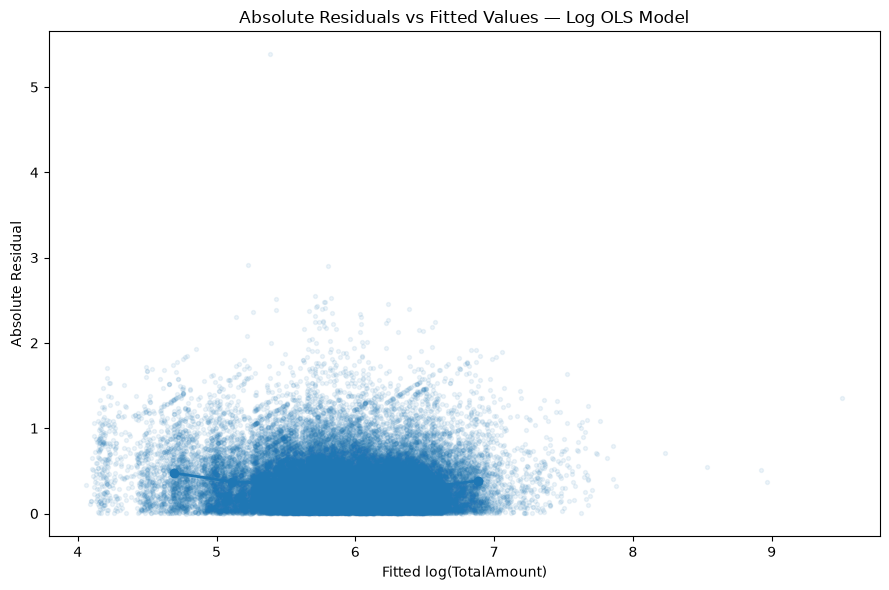

In [16]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    wls_data["Fitted_LogFare"],
    wls_data["Abs_Residual"],
    alpha=0.08,
    s=8
)

ax.plot(
    variance_pattern["Mean_Fitted"],
    variance_pattern["Mean_Abs_Residual"],
    linewidth=2,
    marker="o"
)

ax.set_xlabel("Fitted log(TotalAmount)")
ax.set_ylabel("Absolute Residual")
ax.set_title(
    "Absolute Residuals vs Fitted Values — Log OLS Model"
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "06_absolute_residuals_vs_fitted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Interpretation

Residual magnitude varies systematically with the fitted log fare.

Mean absolute residuals are relatively high at both ends of the fitted range and lower through the middle, producing an approximate U-shaped pattern. A second-order function of the fitted response is therefore considered for the initial variance model.

### 4.2 Estimate the Standard-Deviation Function

Following the empirical WLS procedure, absolute OLS residuals are used to estimate the error standard deviation.

The observed U-shaped pattern motivates comparison of first- and second-order functions of the fitted log fare.

In [17]:
sd_linear = smf.ols(
    "Abs_Residual ~ Fitted_LogFare",
    data=wls_data
).fit()

sd_quadratic = smf.ols(
    "Abs_Residual ~ Fitted_LogFare + I(Fitted_LogFare**2)",
    data=wls_data
).fit()

variance_model_comparison = pd.DataFrame({
    "Model": [
        "Linear",
        "Quadratic"
    ],
    "R_squared": [
        sd_linear.rsquared,
        sd_quadratic.rsquared
    ],
    "Adjusted_R_squared": [
        sd_linear.rsquared_adj,
        sd_quadratic.rsquared_adj
    ],
    "SSE": [
        sd_linear.ssr,
        sd_quadratic.ssr
    ]
})

display(variance_model_comparison)

,Model,R_squared,Adjusted_R_squared,SSE
0,Linear,0.006079,0.006057,3938.381842
1,Quadratic,0.018071,0.018028,3890.862897


In [18]:
print(sd_quadratic.summary().tables[1])

                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  3.2169      0.113     28.548      0.000       2.996       3.438
Fitted_LogFare            -0.9519      0.039    -24.539      0.000      -1.028      -0.876
I(Fitted_LogFare ** 2)     0.0780      0.003     23.454      0.000       0.072       0.085


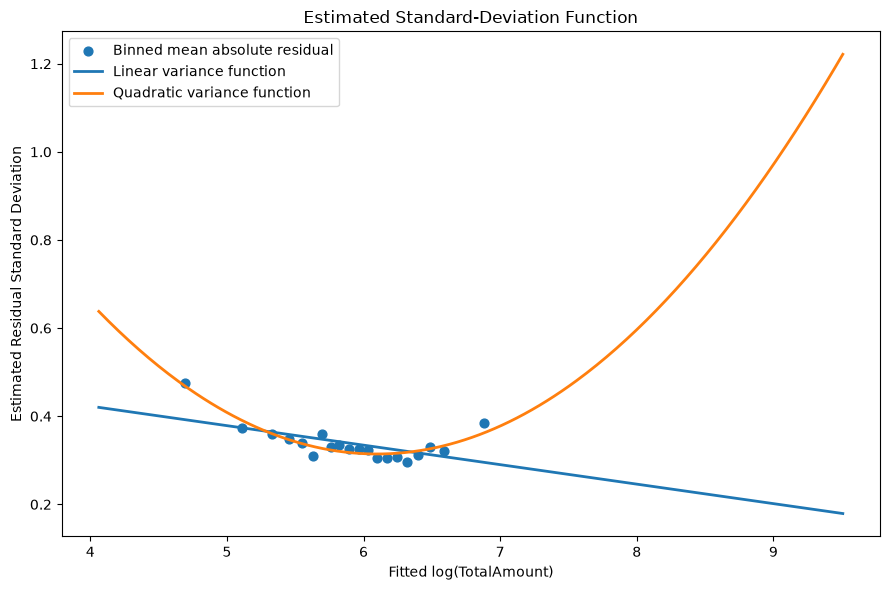

In [19]:
fitted_grid = np.linspace(
    wls_data["Fitted_LogFare"].min(),
    wls_data["Fitted_LogFare"].max(),
    300
)

plot_data = pd.DataFrame({
    "Fitted_LogFare": fitted_grid
})

linear_sd_fit = sd_linear.predict(
    plot_data
)

quadratic_sd_fit = sd_quadratic.predict(
    plot_data
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    variance_pattern["Mean_Fitted"],
    variance_pattern["Mean_Abs_Residual"],
    s=40,
    label="Binned mean absolute residual"
)

ax.plot(
    fitted_grid,
    linear_sd_fit,
    linewidth=2,
    label="Linear variance function"
)

ax.plot(
    fitted_grid,
    quadratic_sd_fit,
    linewidth=2,
    label="Quadratic variance function"
)

ax.set_xlabel("Fitted log(TotalAmount)")
ax.set_ylabel("Estimated Residual Standard Deviation")
ax.set_title(
    "Estimated Standard-Deviation Function"
)

ax.legend()

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "06_standard_deviation_function.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Interpretation

The quadratic specification captures the observed U-shaped pattern better than the linear alternative, with adjusted $R^2$ increasing from approximately 0.006 to 0.018.

However, the auxiliary fit remains weak overall and the quadratic curve rises sharply in the sparsely populated upper fitted range.

The quadratic specification is therefore treated as an initial empirical approximation of the error standard deviation and is evaluated further through WLS residual diagnostics.

### 4.3 Assess the Proposed WLS Weights

Before applying WLS, the fitted standard deviations from the auxiliary regression are examined to ensure that the implied weights are positive and reasonably behaved.

In [20]:
estimated_sd = sd_quadratic.fittedvalues.to_numpy()

print(f"Minimum estimated SD: {estimated_sd.min():.6f}")
print(f"Maximum estimated SD: {estimated_sd.max():.6f}")

print(
    "\nEstimated SD percentiles:"
)

print(
    pd.Series(estimated_sd).describe(
        percentiles=[
            0.01,
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99
        ]
    )
)

Minimum estimated SD: 0.314306
Maximum estimated SD: 1.221398

Estimated SD percentiles:
count    45043.000000
mean         0.338528
std          0.039872
min          0.314306
1%           0.314310
5%           0.314394
25%          0.316748
50%          0.324095
75%          0.341664
95%          0.416170
99%          0.512936
max          1.221398
dtype: float64


In [21]:
proposed_weights = (
    1 / estimated_sd**2
)

print(
    "\nProposed WLS weight percentiles:"
)

print(
    pd.Series(proposed_weights).describe(
        percentiles=[
            0.01,
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99
        ]
    )
)

print(
    f"\nMax / min weight ratio: "
    f"{proposed_weights.max() / proposed_weights.min():.2f}"
)


Proposed WLS weight percentiles:
count    45043.000000
mean         8.977299
std          1.423905
min          0.670326
1%           3.800797
5%           5.773752
25%          8.566480
50%          9.520419
75%          9.967206
95%         10.117025
99%         10.122384
max         10.122637
dtype: float64

Max / min weight ratio: 15.10


#### Interpretation

All fitted standard deviations are positive, ranging from approximately 0.31 to 1.22.

The implied weights are reasonably behaved, with a maximum-to-minimum ratio of approximately 15.1. The weighting scheme is therefore sufficiently stable for an initial WLS fit.

### 4.4 Initial Weighted Least Squares Model

The log-response model is re-estimated using the proposed weights.

In [22]:
wls_data["WLS_Weight"] = proposed_weights

wls_model = smf.wls(
    formula=log_formula,
    data=wls_data,
    weights=wls_data["WLS_Weight"]
).fit()

print(f"Observations: {int(wls_model.nobs):,}")

Observations: 45,043


In [23]:
coefficient_comparison = pd.DataFrame({
    "Coefficient": log_model.params.index,
    "Log_OLS": log_model.params.values,
    "Log_WLS": wls_model.params.values
})

coefficient_comparison[
    "Coefficient_Change"
] = (
    coefficient_comparison["Log_WLS"]
    - coefficient_comparison["Log_OLS"]
)

display(
    coefficient_comparison
)

,Coefficient,Log_OLS,Log_WLS,Coefficient_Change
0,Intercept,5.596212,5.602348,6.136011e-03
1,"C(RoundTrip, Treatment(reference=0))[T.1]",0.430609,0.428241,-2.368223e-03
2,"C(OnLine, Treatment(reference=1))[T.0]",0.103595,0.101987,-1.607817e-03
3,"C(PurchaseWindowGroup, Treatment(reference='21...",-0.299511,-0.306994,-7.483465e-03
4,"C(PurchaseWindowGroup, Treatment(reference='21...",-0.304139,-0.318380,-1.424067e-02
...,...,...,...,...
56,"C(OriginState_Model, Treatment(reference='CA')...",0.032854,0.031399,-1.455044e-03
57,"C(OriginState_Model, Treatment(reference='CA')...",-0.016062,-0.019287,-3.224469e-03
58,"C(OriginState_Model, Treatment(reference='CA')...",0.134930,0.139573,4.642982e-03
59,TotalDistance,0.000155,0.000156,9.825458e-07


In [24]:
largest_coefficient_changes = (
    coefficient_comparison
    .assign(
        Abs_Change=lambda x:
        x["Coefficient_Change"].abs()
    )
    .sort_values(
        "Abs_Change",
        ascending=False
    )
    .head(15)
)

display(largest_coefficient_changes)

,Coefficient,Log_OLS,Log_WLS,Coefficient_Change,Abs_Change
50,"C(OriginState_Model, Treatment(reference='CA')...",-0.069125,-0.108826,-0.039701,0.039701
9,"C(RpCarrier_Model, Treatment(reference='AA'))[...",-1.252936,-1.290423,-0.037487,0.037487
52,"C(OriginState_Model, Treatment(reference='CA')...",0.067899,0.083117,0.015218,0.015218
4,"C(PurchaseWindowGroup, Treatment(reference='21...",-0.304139,-0.318380,-0.014241,0.014241
53,"C(OriginState_Model, Treatment(reference='CA')...",0.034639,0.048429,0.013790,0.013790
16,"C(ItinGeoType, Treatment(reference=2))[T.1]",0.045623,0.057634,0.012011,0.012011
17,"C(OriginState_Model, Treatment(reference='CA')...",0.172675,0.160721,-0.011954,0.011954
25,"C(OriginState_Model, Treatment(reference='CA')...",-0.283485,-0.272710,0.010775,0.010775
15,"C(RpCarrier_Model, Treatment(reference='AA'))[...",-1.018678,-1.007928,0.010750,0.010750
55,"C(OriginState_Model, Treatment(reference='CA')...",0.047854,0.057861,0.010007,0.010007


#### Interpretation

The WLS coefficient estimates remain close to those from log OLS. The largest absolute coefficient change is approximately 0.04, while most changes are considerably smaller.

The substantive relationships are therefore stable under the initial weighting scheme. The adequacy of the weights is assessed next using the weighted residuals.

### 4.5 Initial WLS Residual Assessment

If the estimated weights adequately represent the unequal error variances, the weighted residuals should exhibit approximately constant spread.

In [25]:
weighted_residuals = (
    np.sqrt(wls_data["WLS_Weight"].to_numpy())
    * wls_model.resid.to_numpy()
)

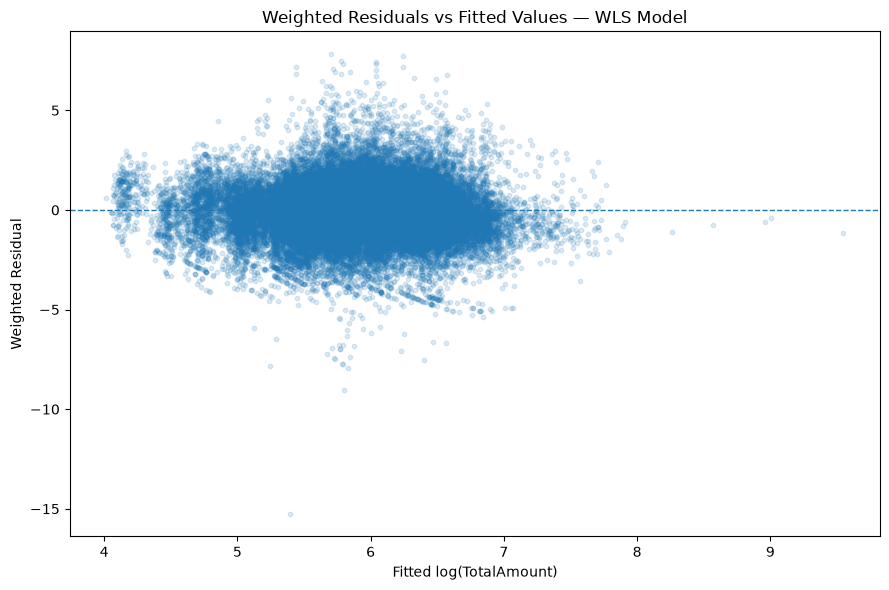

In [26]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    wls_model.fittedvalues,
    weighted_residuals,
    alpha=0.15,
    s=10
)

ax.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

ax.set_xlabel("Fitted log(TotalAmount)")
ax.set_ylabel("Weighted Residual")
ax.set_title(
    "Weighted Residuals vs Fitted Values — WLS Model"
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "06_wls_weighted_residuals_vs_fitted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
wls_bp = het_breuschpagan(
    weighted_residuals,
    wls_model.model.exog
)

wls_bp_results = pd.DataFrame({
    "Statistic": [
        "LM Statistic",
        "LM p-value",
        "F Statistic",
        "F p-value"
    ],
    "Value": wls_bp
})

display(wls_bp_results)

,Statistic,Value
0,LM Statistic,1.233330e+03
1,LM p-value,1.484268e-218
2,F Statistic,2.110556e+01
3,F p-value,6.239684e-222


#### Interpretation

The weighted-residual spread improves under the initial WLS specification, but nonconstant variance remains visible.

The Breusch–Pagan test also continues to reject constant error variance:

$$
LM=1233.33,
\qquad
p<0.001.
$$

The initial variance function therefore provides only a partial correction, motivating one refinement of the estimated standard-deviation function.

### 4.6 Refine the Estimated Standard-Deviation Function

Because the initial weighting scheme does not fully stabilize the residual variance, the standard-deviation function is refined once using `TotalDistance`, `RoundTrip`, and `OnLine` in addition to the fitted log fare.

These variables provide a parsimonious extension using existing itinerary characteristics, without constructing a highly parameterized variance model.

In [28]:
sd_refined = smf.ols(
    """
    Abs_Residual ~
        Fitted_LogFare
        + I(Fitted_LogFare**2)
        + TotalDistance
        + C(RoundTrip, Treatment(reference=0))
        + C(OnLine, Treatment(reference=1))
    """,
    data=wls_data
).fit()

In [29]:
sd_model_comparison = pd.DataFrame({
    "Model": [
        "Quadratic fitted-response model",
        "Refined variance model"
    ],
    "Parameters": [
        int(sd_quadratic.df_model + 1),
        int(sd_refined.df_model + 1)
    ],
    "R_squared": [
        sd_quadratic.rsquared,
        sd_refined.rsquared
    ],
    "Adjusted_R_squared": [
        sd_quadratic.rsquared_adj,
        sd_refined.rsquared_adj
    ],
    "SSE": [
        sd_quadratic.ssr,
        sd_refined.ssr
    ]
})

display(sd_model_comparison)

,Model,Parameters,R_squared,Adjusted_R_squared,SSE
0,Quadratic fitted-response model,3,0.018071,0.018028,3890.862897
1,Refined variance model,6,0.023176,0.023068,3870.635163


In [30]:
print(sd_refined.summary().tables[1])

                                                coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------
Intercept                                     3.1381      0.127     24.723      0.000       2.889       3.387
C(RoundTrip, Treatment(reference=0))[T.1]    -0.0494      0.004    -13.859      0.000      -0.056      -0.042
C(OnLine, Treatment(reference=1))[T.0]        0.0166      0.004      3.744      0.000       0.008       0.025
Fitted_LogFare                               -0.9367      0.045    -20.882      0.000      -1.025      -0.849
I(Fitted_LogFare ** 2)                        0.0782      0.004     19.510      0.000       0.070       0.086
TotalDistance                              5.079e-06   1.52e-06      3.348      0.001    2.11e-06    8.05e-06


In [31]:
refined_sd = sd_refined.fittedvalues.to_numpy()

print(f"Minimum estimated SD: {refined_sd.min():.6f}")
print(f"Maximum estimated SD: {refined_sd.max():.6f}")

print("\nEstimated SD percentiles:")

print(
    pd.Series(refined_sd).describe(
        percentiles=[
            0.01,
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99
        ]
    )
)

Minimum estimated SD: 0.283201
Maximum estimated SD: 1.375029

Estimated SD percentiles:
count    45043.000000
mean         0.338528
std          0.045154
min          0.283201
1%           0.286477
5%           0.289261
25%          0.303409
50%          0.339124
75%          0.355461
95%          0.416775
99%          0.512425
max          1.375029
dtype: float64


In [32]:
refined_weights = 1 / refined_sd**2

print("\nRefined WLS weight percentiles:")

print(
    pd.Series(refined_weights).describe(
        percentiles=[
            0.01,
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99
        ]
    )
)

print(
    f"\nMax / min weight ratio: "
    f"{refined_weights.max() / refined_weights.min():.2f}"
)


Refined WLS weight percentiles:
count    45043.000000
mean         9.100522
std          1.949280
min          0.528904
1%           3.808369
5%           5.757010
25%          7.914373
50%          8.695281
75%         10.862812
95%         11.951423
99%         12.184818
max         12.468410
dtype: float64

Max / min weight ratio: 23.57


#### Interpretation

The refined variance model provides a modest improvement, with adjusted $R^2$ increasing from approximately 0.018 to 0.023.

All fitted standard deviations remain positive and the resulting weights remain usable, although somewhat more dispersed than under the initial specification.

The refined variance function is therefore used for the final WLS fit.

### 4.7 Refined Weighted Least Squares Model

The log-response model is re-estimated using the refined weights, and the weighted residuals are reassessed for constant variance. This is the final empirical WLS specification considered.

In [33]:
wls_data["Refined_WLS_Weight"] = refined_weights

refined_wls_model = smf.wls(
    formula=log_formula,
    data=wls_data,
    weights=wls_data["Refined_WLS_Weight"]
).fit()

print(f"Observations: {int(refined_wls_model.nobs):,}")

Observations: 45,043


In [34]:
refined_weighted_residuals = (
    np.sqrt(
        wls_data["Refined_WLS_Weight"].to_numpy()
    )
    * refined_wls_model.resid.to_numpy()
)

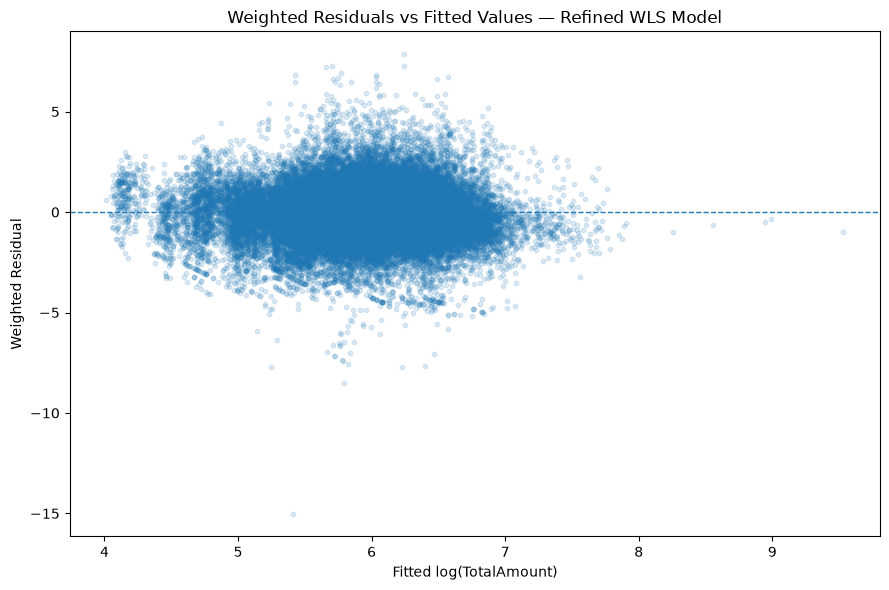

In [35]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    refined_wls_model.fittedvalues,
    refined_weighted_residuals,
    alpha=0.15,
    s=10
)

ax.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

ax.set_xlabel("Fitted log(TotalAmount)")
ax.set_ylabel("Weighted Residual")
ax.set_title(
    "Weighted Residuals vs Fitted Values — Refined WLS Model"
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "06_refined_wls_weighted_residuals_vs_fitted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [36]:
refined_wls_bp = het_breuschpagan(
    refined_weighted_residuals,
    refined_wls_model.model.exog
)

refined_wls_bp_results = pd.DataFrame({
    "Statistic": [
        "LM Statistic",
        "LM p-value",
        "F Statistic",
        "F p-value"
    ],
    "Value": refined_wls_bp
})

display(refined_wls_bp_results)

,Statistic,Value
0,LM Statistic,1.003039e+03
1,LM p-value,3.806648e-171
2,F Statistic,1.707490e+01
3,F p-value,2.557916e-173


In [37]:
heteroskedasticity_comparison_final = pd.DataFrame({
    "Model": [
        "Log OLS",
        "Initial WLS",
        "Refined WLS"
    ],
    "BP_LM": [
        log_bp[0],
        wls_bp[0],
        refined_wls_bp[0]
    ],
    "BP_p_value": [
        log_bp[1],
        wls_bp[1],
        refined_wls_bp[1]
    ]
})

display(heteroskedasticity_comparison_final)

,Model,BP_LM,BP_p_value
0,Log OLS,1681.851629,0.000000e+00
1,Initial WLS,1233.330266,1.484268e-218
2,Refined WLS,1003.038638,3.806648e-171


#### Interpretation

The refined WLS specification further improves variance stability. The Breusch–Pagan LM statistic decreases from 1681.85 under log OLS to 1233.33 under the initial WLS specification and to 1003.04 under refined WLS.

The weighted-residual plot also shows a more balanced spread. However, the Breusch–Pagan test still rejects constant variance at conventional significance levels.

Thus, refined WLS substantially reduces but does not completely eliminate heteroskedasticity. No further variance-function refinement is pursued to avoid unnecessary model complexity and overfitting.

Because the WLS weights are estimated from the sample rather than known, conventional WLS inference should be interpreted as approximate, particularly because some residual heteroskedasticity remains.

The refined log-WLS model is retained as the primary refined specification, with a heteroskedasticity-robust OLS specification considered separately as a robustness benchmark.

## 5. Robustness Check Using White Standard Errors

The refined log-WLS model is retained as the primary specification, but its weights depend on an estimated variance function.

As a robustness benchmark, the same log-response specification is therefore estimated using OLS with White heteroskedasticity-robust standard errors. This approach does not rely on the WLS variance model and provides inference that does not require constant error variance.

Agreement between the two approaches would indicate that the main conclusions are not driven by the particular WLS weighting scheme.

In [38]:
log_model_white = log_model.get_robustcov_results(
    cov_type="HC0"
)

### 5.1 Compare Refined WLS with OLS + White

In [39]:
robustness_comparison = pd.DataFrame({
    "Coefficient": log_model.params.index,
    "Refined_WLS_Estimate": refined_wls_model.params.values,
    "Refined_WLS_SE": refined_wls_model.bse.values,
    "Refined_WLS_p_value": refined_wls_model.pvalues.values,
    "Log_OLS_Estimate": log_model.params.values,
    "White_SE": log_model_white.bse,
    "White_p_value": log_model_white.pvalues
})

robustness_comparison["Estimate_Difference"] = (
    robustness_comparison["Refined_WLS_Estimate"]
    - robustness_comparison["Log_OLS_Estimate"]
)

robustness_comparison["Abs_Estimate_Difference"] = (
    robustness_comparison["Estimate_Difference"].abs()
)

robustness_comparison[
    "Refined_WLS_Significant_5pct"
] = (
    robustness_comparison["Refined_WLS_p_value"] < 0.05
)

robustness_comparison[
    "White_Significant_5pct"
] = (
    robustness_comparison["White_p_value"] < 0.05
)

display(
    robustness_comparison.sort_values(
        "Abs_Estimate_Difference",
        ascending=False
    ).head(15)
)

,Coefficient,Refined_WLS_Estimate,Refined_WLS_SE,Refined_WLS_p_value,Log_OLS_Estimate,White_SE,White_p_value,Estimate_Difference,Abs_Estimate_Difference,Refined_WLS_Significant_5pct,White_Significant_5pct
9,"C(RpCarrier_Model, Treatment(reference='AA'))[...",-1.296832,0.014070,0.000000e+00,-1.252936,0.015232,0.000000e+00,-0.043896,0.043896,True,True
50,"C(OriginState_Model, Treatment(reference='CA')...",-0.096223,0.027836,5.472168e-04,-0.069125,0.025354,6.405775e-03,-0.027098,0.027098,True,True
25,"C(OriginState_Model, Treatment(reference='CA')...",-0.303951,0.020382,3.581983e-50,-0.283485,0.022010,6.849482e-38,-0.020466,0.020466,True,True
53,"C(OriginState_Model, Treatment(reference='CA')...",0.053405,0.015328,4.941352e-04,0.034639,0.016023,3.064132e-02,0.018767,0.018767,True,True
52,"C(OriginState_Model, Treatment(reference='CA')...",0.086278,0.021544,6.219265e-05,0.067899,0.021949,1.979096e-03,0.018379,0.018379,True,True
34,"C(OriginState_Model, Treatment(reference='CA')...",0.036341,0.042086,3.878649e-01,0.020701,0.041537,6.182196e-01,0.015640,0.015640,False,False
46,"C(OriginState_Model, Treatment(reference='CA')...",0.150541,0.025559,3.892283e-09,0.135624,0.023498,7.894668e-09,0.014917,0.014917,True,True
39,"C(OriginState_Model, Treatment(reference='CA')...",0.077021,0.013333,7.657674e-09,0.062396,0.013299,2.718604e-06,0.014626,0.014626,True,True
16,"C(ItinGeoType, Treatment(reference=2))[T.1]",0.060215,0.011518,1.720906e-07,0.045623,0.011715,9.865534e-05,0.014592,0.014592,True,True
33,"C(OriginState_Model, Treatment(reference='CA')...",0.111336,0.018849,3.514122e-09,0.097460,0.017855,4.827143e-08,0.013876,0.013876,True,True


In [40]:
robustness_significance_changes = robustness_comparison[
    robustness_comparison[
        "Refined_WLS_Significant_5pct"
    ]
    != robustness_comparison[
        "White_Significant_5pct"
    ]
]

display(robustness_significance_changes)

print(
    "Number of coefficients whose 5% significance "
    "conclusion differs:",
    len(robustness_significance_changes)
)

,Coefficient,Refined_WLS_Estimate,Refined_WLS_SE,Refined_WLS_p_value,Log_OLS_Estimate,White_SE,White_p_value,Estimate_Difference,Abs_Estimate_Difference,Refined_WLS_Significant_5pct,White_Significant_5pct
32,"C(OriginState_Model, Treatment(reference='CA')...",-0.026129,0.014736,0.076206,-0.033230,0.016000,0.037821,0.00710,0.00710,False,True
42,"C(OriginState_Model, Treatment(reference='CA')...",0.058275,0.030584,0.056729,0.058305,0.026874,0.030046,-0.00003,0.00003,False,True


Number of coefficients whose 5% significance conclusion differs: 2


#### Interpretation

The refined WLS and log-OLS specifications produce broadly similar coefficient estimates. Even among the coefficients with the largest differences, the absolute changes are relatively small.

The 5% significance conclusion differs for only 2 of the 61 coefficients, both of which are origin-state dummy coefficients close to the significance threshold. They are insignificant under refined WLS but significant under OLS with White robust standard errors.

Overall, the main coefficient-level conclusions are stable across the two approaches. This suggests that the substantive findings are not driven primarily by the particular WLS weighting scheme.

### 5.2 Effect of White Robust Standard Errors

The effect of the White correction is also examined within the log-OLS specification by comparing conventional and heteroskedasticity-robust standard errors.

In [41]:
white_comparison = pd.DataFrame({
    "Coefficient": log_model.params.index,
    "Estimate": log_model.params.values,
    "OLS_SE": log_model.bse.values,
    "White_SE": log_model_white.bse,
    "OLS_p_value": log_model.pvalues.values,
    "White_p_value": log_model_white.pvalues
})

white_comparison["SE_Change_Percent"] = (
    (
        white_comparison["White_SE"]
        / white_comparison["OLS_SE"]
    ) - 1
) * 100

white_comparison["Abs_SE_Change_Percent"] = (
    white_comparison["SE_Change_Percent"].abs()
)

display(
    white_comparison.sort_values(
        "Abs_SE_Change_Percent",
        ascending=False
    ).head(15)
)

,Coefficient,Estimate,OLS_SE,White_SE,OLS_p_value,White_p_value,SE_Change_Percent,Abs_SE_Change_Percent
11,"C(RpCarrier_Model, Treatment(reference='AA'))[...",-0.448025,0.033774,0.062570,4.363211e-40,8.167331e-13,85.262612,85.262612
12,"C(RpCarrier_Model, Treatment(reference='AA'))[...",-0.584693,0.025787,0.019071,3.493284e-113,2.588508e-204,-26.043879,26.043879
9,"C(RpCarrier_Model, Treatment(reference='AA'))[...",-1.252936,0.012364,0.015232,0.000000e+00,0.000000e+00,23.190215,23.190215
17,"C(OriginState_Model, Treatment(reference='CA')...",0.172675,0.027289,0.033080,2.513925e-10,1.798030e-07,21.219862,21.219862
42,"C(OriginState_Model, Treatment(reference='CA')...",0.058305,0.031950,0.026874,6.802832e-02,3.004609e-02,-15.887523,15.887523
46,"C(OriginState_Model, Treatment(reference='CA')...",0.135624,0.026606,0.023498,3.455076e-07,7.894668e-09,-11.682045,11.682045
19,"C(OriginState_Model, Treatment(reference='CA')...",0.118322,0.033724,0.029860,4.510861e-04,7.427283e-05,-11.458246,11.458246
57,"C(OriginState_Model, Treatment(reference='CA')...",-0.016062,0.013883,0.015437,2.472991e-01,2.980992e-01,11.188453,11.188453
25,"C(OriginState_Model, Treatment(reference='CA')...",-0.283485,0.020040,0.022010,2.473674e-45,6.849482e-38,9.833197,9.833197
43,"C(OriginState_Model, Treatment(reference='CA')...",0.008558,0.015510,0.017031,5.810987e-01,6.153180e-01,9.807762,9.807762


In [42]:
white_comparison["OLS_Significant_5pct"] = (
    white_comparison["OLS_p_value"] < 0.05
)

white_comparison["White_Significant_5pct"] = (
    white_comparison["White_p_value"] < 0.05
)

white_significance_changes = white_comparison[
    white_comparison["OLS_Significant_5pct"]
    != white_comparison["White_Significant_5pct"]
]

display(white_significance_changes)

print(
    "Number of coefficients whose 5% significance "
    "conclusion changes:",
    len(white_significance_changes)
)

,Coefficient,Estimate,OLS_SE,White_SE,OLS_p_value,White_p_value,SE_Change_Percent,Abs_SE_Change_Percent,OLS_Significant_5pct,White_Significant_5pct
42,"C(OriginState_Model, Treatment(reference='CA')...",0.058305,0.03195,0.026874,0.068028,0.030046,-15.887523,15.887523,False,True


Number of coefficients whose 5% significance conclusion changes: 1


#### Interpretation

White robust standard errors differ from the conventional OLS standard errors for several coefficients, with some relatively large percentage changes.

However, only 1 of the 61 coefficients changes its 5% significance classification after applying the White correction.

Thus, heteroskedasticity affects the estimated precision of some individual coefficients, but the overall inferential conclusions of the log-response OLS model remain largely unchanged.

### 5.3 Export Robustness Results

In [43]:
robustness_comparison.to_csv(
    OUTPUT_DIR / "06_wls_white_robustness_comparison.csv",
    index=False
)

white_comparison.to_csv(
    OUTPUT_DIR / "06_white_robust_inference.csv",
    index=False
)

## 6. Reassess Candidate Specification After Transformation

The response transformation may change the explanatory contribution of individual predictors.

Because `Coupons` was the only variable distinguishing the two main candidates from Notebook 04, the full and reduced specifications are reassessed on the log-response scale before both candidate models are carried forward to validation.

In [44]:
reduced_log_formula = """
LogTotalAmount ~
    TotalDistance
    + C(RoundTrip, Treatment(reference=0))
    + C(OnLine, Treatment(reference=1))
    + C(PurchaseWindowGroup, Treatment(reference='21AP'))
    + C(RpCarrier_Model, Treatment(reference='AA'))
    + C(ItinGeoType, Treatment(reference=2))
    + C(OriginState_Model, Treatment(reference='CA'))
"""

reduced_log_model = smf.ols(
    formula=reduced_log_formula,
    data=model_df
).fit()

In [45]:
log_candidate_comparison = pd.DataFrame({
    "Model": [
        "Full log model",
        "Log model without Coupons"
    ],
    "Parameters": [
        int(log_model.df_model + 1),
        int(reduced_log_model.df_model + 1)
    ],
    "R_squared": [
        log_model.rsquared,
        reduced_log_model.rsquared
    ],
    "Adjusted_R_squared": [
        log_model.rsquared_adj,
        reduced_log_model.rsquared_adj
    ],
    "AIC": [
        log_model.aic,
        reduced_log_model.aic
    ],
    "BIC": [
        log_model.bic,
        reduced_log_model.bic
    ]
})

display(log_candidate_comparison)

,Model,Parameters,R_squared,Adjusted_R_squared,AIC,BIC
0,Full log model,61,0.574214,0.573646,56030.081658,56561.719403
1,Log model without Coupons,60,0.574123,0.573565,56037.656061,56560.578433


In [46]:
coupons_position = (
    log_model.params.index.tolist()
    .index("Coupons")
)

coupons_robust_result = pd.DataFrame({
    "Estimate": [
        log_model.params["Coupons"]
    ],
    "White_SE": [
        log_model_white.bse[coupons_position]
    ],
    "White_p_value": [
        log_model_white.pvalues[coupons_position]
    ]
})

display(coupons_robust_result)

,Estimate,White_SE,White_p_value
0,0.011635,0.003727,0.0018


In [47]:
coupons_wls_result = pd.DataFrame({
    "Estimate": [
        refined_wls_model.params["Coupons"]
    ],
    "WLS_SE": [
        refined_wls_model.bse["Coupons"]
    ],
    "WLS_p_value": [
        refined_wls_model.pvalues["Coupons"]
    ]
})

display(coupons_wls_result)

,Estimate,WLS_SE,WLS_p_value
0,0.01314,0.003598,0.00026


#### Interpretation

The two log-response specifications have very similar overall fit. The full model performs slightly better on adjusted $R^2$ and AIC, while BIC marginally favors the specification without `Coupons`.

`Coupons` is statistically significant under the refined WLS specification and remains significant under White robust inference:

$$
\hat{\beta}_{Coupons}=0.0116,
\qquad
p=0.0018
$$

under the White robustness benchmark.

Given its additional explanatory contribution and the negligible difference in model complexity, the full eight-block specification is provisionally preferred.

However, the reduced seven-block specification remains a plausible alternative because overall fit is nearly identical and BIC marginally favors the simpler model.

Both specifications are therefore carried forward to validation, where out-of-sample performance and coefficient stability will be used to support the final model choice.

In [48]:
log_candidate_comparison.to_csv(
    OUTPUT_DIR / "06_log_candidate_comparison.csv",
    index=False
)

## 7. Model Refinement Summary

The original level specification exhibited substantial residual skewness and heteroskedasticity.

Transforming `TotalAmount` to the log scale substantially improved the residual distribution, although unequal variance remained. Empirical WLS was therefore applied, and a parsimonious refinement of the estimated variance function further improved variance stability.

Residual heteroskedasticity remains statistically detectable, so exact constant variance cannot be claimed. Nevertheless, refined WLS materially reduces the problem and is retained as the primary estimation approach.

As a robustness benchmark, log OLS with White heteroskedasticity-robust standard errors produces broadly similar coefficient and significance conclusions, indicating that the main findings are not driven by the particular WLS weighting scheme.

The eight-block specification is provisionally preferred because `Coupons` remains statistically significant and provides additional explanatory information.

The eight-block and seven-block specifications are both carried forward to the held-out validation sample in Notebook 07, where the final model choice will be based on out-of-sample performance, coefficient stability, and parsimony.